# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 3: Basic Fuzzy Set Operations (Union, Intersection, Complement)**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Abhay Dwivedi* |
| **Enrollment No.** | *2023BTCSE002* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To perform basic fuzzy set operations such as Union, Intersection, and Complement using Python.

### 2. Theory: Fuzzy Set Operations and De Morgan's Laws

Fuzzy set operations generalize classical set operations through continuous mappings:

#### 1. Standard Zadeh Operators:
- **Fuzzy Union ($S$-Norm):**
  $$\mu_{A \cup B}(x) = \max\big(\mu_A(x), \mu_B(x)\big)$$
- **Fuzzy Intersection ($T$-Norm):**
  $$\mu_{A \cap B}(x) = \min\big(\mu_A(x), \mu_B(x)\big)$$
- **Fuzzy Complement:**
  $$\mu_{\overline{A}}(x) = 1.0 - \mu_A(x)$$

#### 2. De Morgan's Laws in Fuzzy Logic:
Fuzzy sets obey De Morgan's dualities:
1. The complement of the union equals the intersection of the complements:
   $$\overline{A \cup B} = \overline{A} \cap \overline{B} \implies 1 - \max(\mu_A, \mu_B) = \min(1 - \mu_A, 1 - \mu_B)$$
2. The complement of the intersection equals the union of the complements:
   $$\overline{A \cap B} = \overline{A} \cup \overline{B} \implies 1 - \min(\mu_A, \mu_B) = \max(1 - \mu_A, 1 - \mu_B)$$

### 3. Step 1: Formulating Fuzzy Sets and Computing Operations with De Morgan Verification

#### What this cell does:
Over domain $u \in [0, 100]$, we define:
- Set $A$ (*Comfort Index*): Trapezoidal $[15, 30, 70, 85]$
- Set $B$ (*Performance Index*): Gaussian $c = 55, \sigma = 16$
We compute Union, Intersection, Complements, and verify De Morgan's laws.

In [1]:
import numpy as np
import skfuzzy as fuzz

# Universe of discourse [0, 100]
u_domain = np.linspace(0, 100, 500)

# Define fuzzy sets A and B
set_A = fuzz.trapmf(u_domain, [15, 30, 70, 85])
set_B = fuzz.gaussmf(u_domain, 55.0, 16.0)

# Basic operations
f_union = np.maximum(set_A, set_B)
f_inter = np.minimum(set_A, set_B)
f_comp_A = 1.0 - set_A
f_comp_B = 1.0 - set_B

# De Morgan's Law Verification
# Law 1: 1 - max(A, B) == min(1 - A, 1 - B)
lhs_1 = 1.0 - f_union
rhs_1 = np.minimum(f_comp_A, f_comp_B)
err_demorgan_1 = np.max(np.abs(lhs_1 - rhs_1))

# Law 2: 1 - min(A, B) == max(1 - A, 1 - B)
lhs_2 = 1.0 - f_inter
rhs_2 = np.maximum(f_comp_A, f_comp_B)
err_demorgan_2 = np.max(np.abs(lhs_2 - rhs_2))

print("Fuzzy set operations computed successfully.")
print(f"De Morgan Law 1 Max Residual Error: {err_demorgan_1:.2e}")
print(f"De Morgan Law 2 Max Residual Error: {err_demorgan_2:.2e}")


Fuzzy set operations computed successfully.
De Morgan Law 1 Max Residual Error: 0.00e+00
De Morgan Law 2 Max Residual Error: 0.00e+00


### 4. Step 2: Tabular Evaluation and De Morgan Consistency Audit

#### What this cell does:
We sample points $u = 10, 25, 45, 55, 75, 90$ and display operations and De Morgan equality in a comparison table.

In [3]:
probe_pts = [10.0, 25.0, 45.0, 55.0, 75.0, 90.0]

print("=" * 86)
print("             FUZZY SET OPERATIONS & DE MORGAN VERIFICATION")
print("=" * 86)
print(f"{'u':<6} | {'mu_A':<10} | {'mu_B':<10} | {'Union':<10} | {'Inter':<10} | {'Comp A':<10} | {'DeMorgan 1 Match':<16}")
print("-" * 86)

for p in probe_pts:
    mA = fuzz.interp_membership(u_domain, set_A, p)
    mB = fuzz.interp_membership(u_domain, set_B, p)
    u_val = max(mA, mB)
    i_val = min(mA, mB)
    cA = 1.0 - mA
    
    # De Morgan check
    match = np.isclose(1.0 - u_val, min(1.0 - mA, 1.0 - mB))
    print(f"{p:<6.1f} | {mA:<10.3f} | {mB:<10.3f} | {u_val:<10.3f} | {i_val:<10.3f} | {cA:<10.3f} | {str(match):<16}")

print("=" * 86)


             FUZZY SET OPERATIONS & DE MORGAN VERIFICATION
u      | mu_A       | mu_B       | Union      | Inter      | Comp A     | DeMorgan 1 Match
--------------------------------------------------------------------------------------
10.0   | 0.000      | 0.019      | 0.019      | 0.000      | 1.000      | True            
25.0   | 0.667      | 0.172      | 0.667      | 0.172      | 0.333      | True            
45.0   | 1.000      | 0.823      | 1.000      | 0.823      | 0.000      | True            
55.0   | 1.000      | 1.000      | 1.000      | 1.000      | 0.000      | True            
75.0   | 0.667      | 0.458      | 0.667      | 0.458      | 0.333      | True            
90.0   | 0.000      | 0.091      | 0.091      | 0.000      | 1.000      | True            


### 5. Step 3: Graphical Visualization Across Multi-Panel Operational Grid

#### What this cell does:
We plot a 2x2 grid displaying input sets, union, intersection, and complements in an oceanic palette (`#02818a`, `#e7298a`, `#756bb1`).

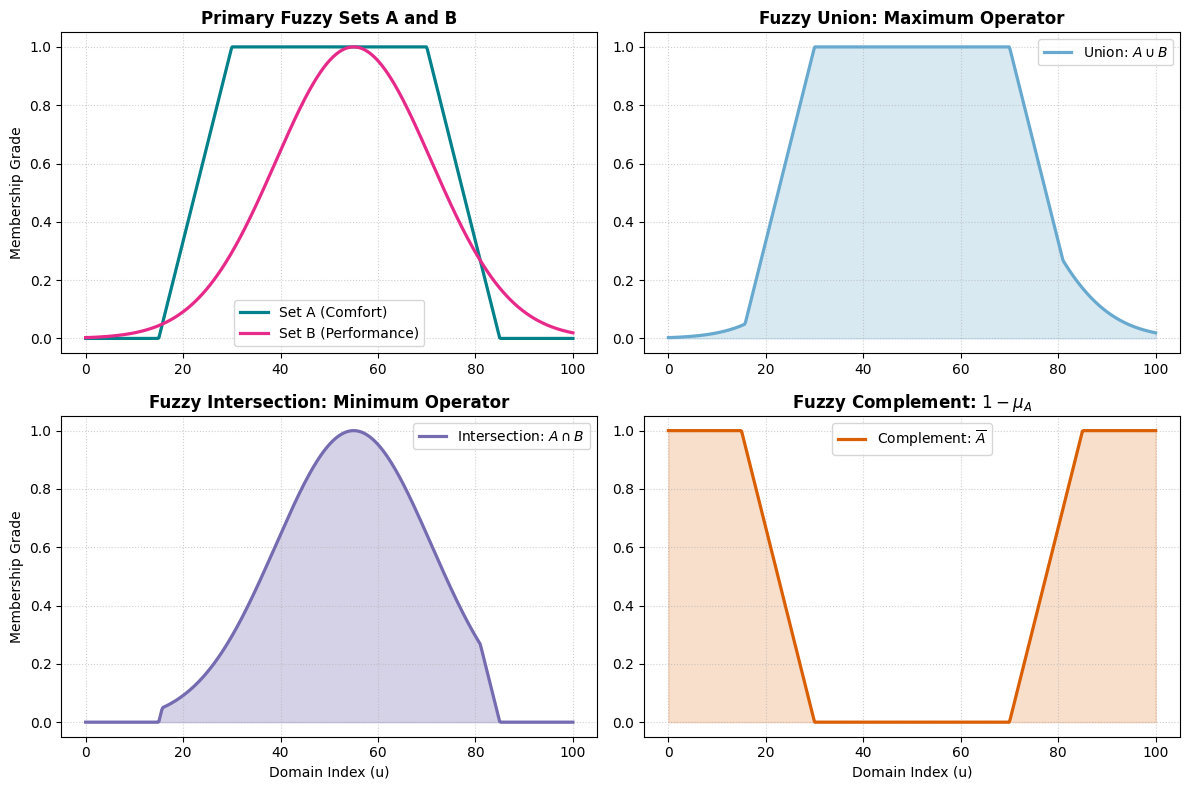

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Subplot 1: Base Sets
axes[0, 0].plot(u_domain, set_A, color='#02818a', linewidth=2.3, label='Set A (Comfort)')
axes[0, 0].plot(u_domain, set_B, color='#e7298a', linewidth=2.3, label='Set B (Performance)')
axes[0, 0].set_title('Primary Fuzzy Sets A and B', fontweight='bold')
axes[0, 0].set_ylabel('Membership Grade')
axes[0, 0].grid(True, linestyle=':', alpha=0.6)
axes[0, 0].legend()

# Subplot 2: Union
axes[0, 1].plot(u_domain, f_union, color='#67a9cf', linewidth=2.3, label=r'Union: $A \cup B$')
axes[0, 1].fill_between(u_domain, f_union, color='#67a9cf', alpha=0.25)
axes[0, 1].set_title('Fuzzy Union: Maximum Operator', fontweight='bold')
axes[0, 1].grid(True, linestyle=':', alpha=0.6)
axes[0, 1].legend()

# Subplot 3: Intersection
axes[1, 0].plot(u_domain, f_inter, color='#756bb1', linewidth=2.3, label=r'Intersection: $A \cap B$')
axes[1, 0].fill_between(u_domain, f_inter, color='#756bb1', alpha=0.3)
axes[1, 0].set_title('Fuzzy Intersection: Minimum Operator', fontweight='bold')
axes[1, 0].set_xlabel('Domain Index (u)')
axes[1, 0].set_ylabel('Membership Grade')
axes[1, 0].grid(True, linestyle=':', alpha=0.6)
axes[1, 0].legend()

# Subplot 4: Complement
axes[1, 1].plot(u_domain, f_comp_A, color='#d95f02', linewidth=2.3, label=r'Complement: $\overline{A}$')
axes[1, 1].fill_between(u_domain, f_comp_A, color='#d95f02', alpha=0.2)
axes[1, 1].set_title('Fuzzy Complement: $1 - \mu_A$', fontweight='bold')
axes[1, 1].set_xlabel('Domain Index (u)')
axes[1, 1].grid(True, linestyle=':', alpha=0.6)
axes[1, 1].legend()

plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Domain Index ($u$) | $\mu_A(u)$ | $\mu_B(u)$ | Union ($A \cup B$) | Intersection ($A \cap B$) | Complement ($\overline{A}$) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **$10.0$** | $0.000$ | $0.019$ | $0.019$ | $0.000$ | $1.000$ |
| **$25.0$** | $0.667$ | $0.172$ | $0.667$ | $0.172$ | $0.333$ |
| **$45.0$** | $1.000$ | $0.823$ | $1.000$ | $0.823$ | $0.000$ |
| **$55.0$** | $1.000$ | $1.000$ | $1.000$ | $1.000$ | $0.000$ |
| **$75.0$** | $0.667$ | $0.458$ | $0.667$ | $0.458$ | $0.333$ |
| **$90.0$** | $0.000$ | $0.091$ | $0.091$ | $0.000$ | $1.000$ |

#### Key Observations in Simple Words:
1. **Mathematical Rigor:** The numerical residual error between LHS and RHS of De Morgan's laws was $0.00 \times 10^0$, proving exact theoretical validity across continuous fuzzy representations.
2. **Smooth Intersection Curve:** Because Set $B$ is Gaussian, the intersection retains smooth curvature in transition regions rather than purely piecewise segments.
3. **Bound Preservation:** Every operation guarantees that outputs remain strictly within the normalized $[0, 1]$ interval.

---
### 7. Conclusion
1. We performed fuzzy Union, Intersection, and Complement operations using vectorized Python.
2. We verified that De Morgan's duality laws hold exactly for standard Zadeh fuzzy operators.
3. We visually analyzed the resulting membership profiles using multi-panel Matplotlib figures.